# Probabilistic Power Flow on the IEEE European LV Test Feeder: Active Subspaces of a Bus Voltage, a Line Current and the Feeder Loss

__Fei Ni__, Electrical Energy Systems Group, Eindhoven University of Technology, Eindhoven, The Netherlands

__Phuong H. Nguyen__, Electrical Energy Systems Group, Eindhoven University of Technology, Eindhoven, The Netherlands

__Joseph F. G. Cobben__, Electrical Energy Systems Group, Eindhoven University of Technology, Eindhoven, and Alliander, Arnhem, The Netherlands

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

The notebook runs in Python 3 with numpy, scipy, matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library (version 1). It reads the shipped CSV files. They were made with OpenDSS, through OpenDSSDirect.py 0.9.4, by `generate_data.py` and `opendss_driver.py` in this directory; regenerating them needs OpenDSSDirect.py (`DATA.md`).

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import active_subspaces as ac
import opendss_driver as od   # names, nominal values, distributions (numpy only); solving needs OpenDSSDirect.py

SEED = 2017                   # the only seed in this notebook (bootstrap)
t_start = time.perf_counter()
QOI = od.QOI_NAMES            # ('V899A', 'I78A', 'PLOSS')
QLAB = {'V899A': r'$V_{899,A}$ (V)', 'I78A': r'$I_{78,A}$ (A)', 'PLOSS': r'$P_{loss}$ (kW)'}
PH = np.array(['A', 'B', 'C'])[od.LOAD_PHASES - 1]
PCOL = {'A': 'C0', 'B': 'C1', 'C': 'C2'}

### Summary

Ni, Nguyen and Cobben [[1]](#R1) propagate the uncertain demands of the 55 single-phase loads of the IEEE European LV Test Feeder through an unbalanced three-phase power flow in OpenDSS, at the on-peak minute 09:26, and build sparse polynomial chaos surrogates of the phase-A voltage at bus 899, the current in line 78 and the feeder loss. We rebuild their base scenario (55 Gaussian load powers) and their 110-input scenario (with uniform power factors) on the published feeder files and compute central-difference gradients through OpenDSS at 1000 Monte Carlo samples per case; two settings the paper leaves open (the load standard deviation, read as 0.1 kW, and OpenDSS's default switch of the loads to constant impedance above 1.05 p.u.) were chosen among four combinations by matching the paper's Latin hypercube probabilities for the bus-899 voltage (its Table VIII), with which our probabilities are then consistent to within sampling error. All three quantities have a one-dimensional active subspace: in the base scenario $\lambda_1/\lambda_2$ is $2.2\times10^{6}$ for the voltage, $8.5\times10^{6}$ for the current and $4.0\times10^{3}$ for the loss, but these very large ratios reflect a response that is nearly linear in the load powers ($\mathbf w_1$ is the least-squares slope direction, $|\cos| = 1.0000000$ for the voltage), not nonlinear low-dimensional structure, and the 110-input scenario, with $\lambda_1/\lambda_2$ of 549 to 2531 and visible curvature in the power factors, is the more informative case.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ inputs, normalized so that $\mathbf x$ has zero mean and identity covariance under its density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a low-degree polynomial in $\mathbf y$ can stand in for $f$. We estimate $\mathbf C$ by the sample average of gradient outer products and assess it with the bootstrap. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

### The model

**Feeder** [1, pp. 699–700; Fig. 2]. The IEEE European LV Test Feeder is a radial 50 Hz distribution feeder with 906 buses and 55 residential loads, each connected to one phase. An 11/0.416 kV transformer at the substation feeds it, and the external medium-voltage grid "is modelled as a voltage source with an impedance". The paper takes the transformer, line and load data from the IEEE PES test-feeder files [3] and models all loads as constant power. We use those files as distributed with OpenDSS (`feeder/`, unchanged; `DATA.md` gives the commit and licence): an 11 kV source at 1.05 p.u. behind its short-circuit impedance, an 800 kVA delta-wye transformer (4 % reactance), 905 three-phase line segments given by positive- and zero-sequence impedances, and 55 single-phase loads with a nominal voltage of 230 V.

**Power flow.** OpenDSS solves the nodal equations of the unbalanced network, with complex node voltages $\mathbf V$, admittance matrix $\mathbf Y$ (lines, transformer and source impedance) and injected currents $\mathbf I$,

$$
\mathbf Y\,\mathbf V = \mathbf I_{\rm src} - \mathbf I_{\rm load}(\mathbf V),\qquad
I_{k}=\begin{cases}\overline{S_k/V_k}, & 0.95\,V_b\le|V_k|\le1.05\,V_b,\\[2pt] \overline{S_k}\,V_k/(1.05\,V_b)^2, & |V_k|>1.05\,V_b,\end{cases}
\qquad S_k = P_k + jP_k\tan(\arccos \mathrm{pf}_k),
$$

for load $k$ at its node, with $V_b = 230$ V (below $0.95\,V_b$ the load is likewise a constant impedance, sized at 0.95 p.u.; the lowest load voltage at the nominal point is 1.0366 p.u., `check_accuracy.py`). This is OpenDSS's constant-power load model with its default voltage limits, as in the distributed files: a "constant power" load whose voltage exceeds 1.05 p.u. draws the power of a constant impedance sized at 1.05 p.u. At the nominal point 43 of the 55 loads are above 1.05 p.u. (`check_accuracy.py`), so this setting matters. The paper says only "constant power"; this setting is this data set's choice, made among the possible readings by matching the paper's Table VIII (comparison below). We tighten OpenDSS's iteration tolerance from $10^{-4}$ to $10^{-12}$ (p.u. change of the node voltages) so that finite differences are not polluted by the iteration error.

**Quantities of interest** [1, pp. 700–701; Table V]: the phase-A voltage magnitude at bus 899, $V_{899,A}$ in V (phase to ground; the paper's main output, its Figs. 3–5 are in volts); the "current of line 78", here the phase-A current magnitude $I_{78,A}$ in A at the bus-72 end of `LINE78` (the phase and the end are this data set's choice); and the "active power loss of the whole feeder", here the total loss of the circuit $P_{loss}$ in kW, lines and transformer together (this data set's choice; the paper does not say whether the transformer is included).

**Inputs.** The time snapshot is "the on-peak moment, i.e., $t$ = 09:26:00" [1, p. 700], point 566 of the feeder's one-minute load shapes [3]; $P_{L_i}$ is the value of load $i$'s shape there, in kW.

- *Base scenario, 55 inputs* [1, p. 700; Table I]: "all loads maintain a constant power factor 0.95", and the active powers "follow Gaussian distribution $N(PL_i, 0.1^2)$, where $PL_i$ is the original active power demand of the $i$-th ($i = 1, \ldots, 50$) load at $t$ = 09:26:00". The index range "1, …, 50" is a misprint: the same sentence, Table I and the text count 55 loads. The second argument is a variance in the units of $PL_i$, so the standard deviation is 0.1 kW for every load, not 10 % of $PL_i$. We chose this reading among the alternatives by matching Table VIII (comparison below); the spread of the paper's Fig. 4 supports it independently.
- *110 inputs* [1, p. 701; Table I]: the 55 active powers as above and "55 Uniform distributed power factors $U(0.85, 0.95)$". Table IV labels this row "Mixed" (the 30 Gaussian + 25 uniform loads of p. 701), while the text and Table I say the 55 active powers are Gaussian; we follow the text and Table I.
- The 140-input scenario adds 30 rooftop PVs "randomly installed at buses with loads" [1, p. 699], whose buses are not given, so it is not built. The IEEE 123-node feeder cases are not built either (their distribution parameters are not printed, Table I).

All inputs are independent. The table printed below comes from `opendss_driver.py`; the last column is the probability that a load's sampled power is negative.

In [2]:
print(f"{'input':9s} {'bus':>4s} {'phase':>5s} {'P_L at 09:26 (kW)':>17s} {'sd (kW)':>8s} {'P(P_i < 0)':>10s}")
for k in range(od.NLOAD):
    print(f'{od.NAMES55[k]:9s} {od.LOAD_BUSES[k]:>4s} {PH[k]:>5s} {od.P_REF[k]:17.3f} {od.SD_P:8.2f} '
          f'{stats.norm.cdf(-od.P_REF[k] / od.SD_P):10.3f}')
print(f'\nsum of P_L: {od.P_REF.sum():.3f} kW (phase A {od.P_REF[PH == "A"].sum():.3f}, '
      f'B {od.P_REF[PH == "B"].sum():.3f}, C {od.P_REF[PH == "C"].sum():.3f}); loads per phase: '
      f'A {np.sum(PH == "A")}, B {np.sum(PH == "B")}, C {np.sum(PH == "C")}')
print(f'110-input case: pf_i ~ U({od.PF_LO}, {od.PF_HI}), sd {od.SD_PF:.5f}; finite-difference steps '
      f'{od.STEPS55[0]:.0e} kW and {od.STEPS110[-1]:.3e}')

input      bus phase P_L at 09:26 (kW)  sd (kW) P(P_i < 0)
P_LOAD1     34     A             0.574     0.10      0.000
P_LOAD2     47     B             0.044     0.10      0.330
P_LOAD3     70     A             0.114     0.10      0.127
P_LOAD4     73     A             0.231     0.10      0.010
P_LOAD5     74     A             0.035     0.10      0.363
P_LOAD6     83     B             0.395     0.10      0.000
P_LOAD7    178     B             0.055     0.10      0.291
P_LOAD8    208     C             2.836     0.10      0.000
P_LOAD9    225     A             0.131     0.10      0.095
P_LOAD10   248     B             2.798     0.10      0.000
P_LOAD11   249     B             0.049     0.10      0.312
P_LOAD12   264     C             0.286     0.10      0.002
P_LOAD13   276     B             2.211     0.10      0.000
P_LOAD14   289     A             0.210     0.10      0.018
P_LOAD15   314     B             2.331     0.10      0.000
P_LOAD16   320     C             0.510     0.10      0.0

Phase A carries 21 loads (17.436 kW at 09:26), phase B 19 (33.698 kW, including the largest, LOAD26, and the third largest, LOAD35) and phase C 15 (6.224 kW). Many loads draw less than 0.1 kW at 09:26, so with a standard deviation of 0.1 kW their sampled power is negative with probability up to 0.390 (LOAD28). A negative $P_i$ is an injection (at power factor 0.95 its reactive power changes sign too). This is outside the physical meaning of a consumption-only load. We keep these samples: the distribution is the paper's, and the comparison with Table VIII below indicates that the paper's runs kept them too (setting the negative powers to 0, or truncating the normal at 0, breaks the match). We count them below.

### Load data

`generate_data.py` drew three samples with numpy's `default_rng`: 1000 Monte Carlo points of the 55-input base scenario (seed 2017055) and 1000 of the 110-input scenario (seed 2017110), each with the three QoIs and their gradients with respect to the physical inputs by central differences through OpenDSS (step 0.01 of each input's standard deviation: $10^{-3}$ kW and $2.887\times10^{-4}$ in pf; checked in `DATA.md`), and 10 000 Latin hypercube points of the base scenario (seed 2017100; uniform LHS mapped through the normal inverse CDF), QoIs only, the analogue of the paper's LHS reference set of $10^5$ trials [1, p. 699]. `nominal.csv` holds the QoIs and the three phase voltages at bus 899 at $P_i = P_{L_i}$.

In [3]:
X55 = np.loadtxt('inputs_55.csv', delimiter=',')            # (1000, 55) P_i in kW
F55 = np.loadtxt('outputs_55.csv', delimiter=',')           # (1000, 3) V899A (V), I78A (A), PLOSS (kW)
G55 = {q: np.loadtxt(f'grad_{q}_55.csv', delimiter=',') for q in QOI}     # (1000, 55) each, per kW
X110 = np.loadtxt('inputs_110.csv', delimiter=',')          # (1000, 110) P_i (kW), then pf_i
F110 = np.loadtxt('outputs_110.csv', delimiter=',')         # (1000, 3)
G110 = {q: np.loadtxt(f'grad_{q}_110.csv', delimiter=',') for q in QOI}   # (1000, 110) each
XL = np.loadtxt('lhs_inputs_55.csv', delimiter=',')         # (10000, 55) Latin hypercube, P_i in kW
FL = np.loadtxt('lhs_outputs_55.csv', delimiter=',')        # (10000, 3)
NOM = np.loadtxt('nominal.csv', delimiter=',')              # (2, 6) pf, V899A, V899B, V899C, I78A, PLOSS
for name, a in [('X55', X55), ('F55', F55), ('G55[V899A]', G55['V899A']), ('X110', X110), ('F110', F110),
                ('G110[V899A]', G110['V899A']), ('XL', XL), ('FL', FL), ('NOM', NOM)]:
    print(f'{name:12s} {a.shape}')

X55          (1000, 55)
F55          (1000, 3)
G55[V899A]   (1000, 55)
X110         (1000, 110)
F110         (1000, 3)
G110[V899A]  (1000, 110)
XL           (10000, 55)
FL           (10000, 3)
NOM          (2, 6)


We check the samples against their distributions (standardized moments; uniform kurtosis for the power factors; one point per stratum in every column of the Latin hypercube), count the negative powers, and check the gradient coordinates by comparing the least-squares slope of each QoI on the standardized inputs with the mean standardized gradient (they agree when the gradients are taken in the stated coordinates and scaled once).

In [4]:
Z55 = (X55 - od.MEAN55) / od.SD55
Z110 = (X110 - od.MEAN110) / od.SD110
ZL = (XL - od.MEAN55) / od.SD55
kurt = lambda Z: np.mean((Z - Z.mean(0))**4, 0) / Z.var(0)**2
print(f'55-input set: standardized means {Z55.mean(0).min():+.3f} to {Z55.mean(0).max():+.3f}, sds '
      f'{Z55.std(0).min():.3f} to {Z55.std(0).max():.3f}, kurtosis {kurt(Z55).min():.2f} to {kurt(Z55).max():.2f} (Gaussian 3)')
U = X110[:, 55:]
print(f'110-input set: P part kurtosis {kurt(Z110[:, :55]).min():.2f} to {kurt(Z110[:, :55]).max():.2f}; pf in '
      f'[{U.min():.4f}, {U.max():.4f}], kurtosis {kurt(U).min():.2f} to {kurt(U).max():.2f} (uniform 1.8)')
bins = np.floor(stats.norm.cdf(ZL) * len(XL)).astype(int)
print(f'LHS set: every column has one point in each of the {len(XL)} equal-probability strata: '
      f'{all(len(np.unique(bins[:, j])) == len(XL) for j in range(55))}')
for name, X in [('55-input', X55), ('110-input', X110[:, :55]), ('LHS', XL)]:
    neg = X < 0
    print(f'{name:9s}: {neg.mean() * 100:.2f} % of the P_i are negative (expected '
          f'{stats.norm.cdf(-od.P_REF / od.SD_P).mean() * 100:.2f} %); {np.mean(neg.any(1)) * 100:.1f} % of rows '
          f'have at least one; duplicate rows {len(X) - len(np.unique(X, axis=0))}')
for case, Z, F, G, sd in [('55', Z55, F55, G55, od.SD55), ('110', Z110, F110, G110, od.SD110)]:
    for i, q in enumerate(QOI):
        b = np.linalg.lstsq(np.column_stack([np.ones(len(Z)), Z]), F[:, i], rcond=None)[0][1:]
        g = (G[q] * sd).mean(0)
        print(f'{case:>3s} inputs, {q:5s}: mean {F[:, i].mean():9.4f}, sd {F[:, i].std(ddof=1):.4f}; '
              f'cosine(least-squares slope, mean gradient) = {b @ g / np.linalg.norm(b) / np.linalg.norm(g):.6f}')

55-input set: standardized means -0.064 to +0.052, sds 0.945 to 1.051, kurtosis 2.72 to 3.37 (Gaussian 3)
110-input set: P part kurtosis 2.64 to 3.41; pf in [0.8500, 0.9500], kurtosis 1.72 to 1.90 (uniform 1.8)


LHS set: every column has one point in each of the 10000 equal-probability strata: True
55-input : 11.89 % of the P_i are negative (expected 11.97 %); 100.0 % of rows have at least one; duplicate rows 0
110-input: 11.83 % of the P_i are negative (expected 11.97 %); 100.0 % of rows have at least one; duplicate rows 0
LHS      : 11.97 % of the P_i are negative (expected 11.97 %); 100.0 % of rows have at least one; duplicate rows 0
 55 inputs, V899A: mean  250.3754, sd 0.2063; cosine(least-squares slope, mean gradient) = 1.000000
 55 inputs, I78A : mean   73.1879, sd 1.8071; cosine(least-squares slope, mean gradient) = 1.000000
 55 inputs, PLOSS: mean    2.0898, sd 0.0466; cosine(least-squares slope, mean gradient) = 0.999990
110 inputs, V899A: mean  250.7713, sd 0.2919; cosine(least-squares slope, mean gradient) = 0.999892
110 inputs, I78A : mean   77.4569, sd 2.4822; cosine(least-squares slope, mean gradient) = 0.999944
110 inputs, PLOSS: mean    2.3373, sd 0.0881; cosine(least-squares 

The samples match their distributions: standardized means within $\pm0.064$, sample kurtoses 2.72–3.37 for the Gaussian inputs (2.64–3.41 in the 110-input set) and 1.72–1.90 for the uniform power factors, and the Latin hypercube has one point in every stratum of every column. About 12 % of the sampled powers are negative (11.89 %, 11.83 % and 11.97 % in the three sets; 11.97 % expected), and every row has at least one negative power, so no subset of rows would remove them. The least-squares slopes and mean gradients agree to a cosine of 1.000000 for the voltage and the current of the base scenario, and of 0.999831 or more in every case, which confirms the gradient coordinates. In the base scenario $V_{899,A}$ has mean 250.3754 V and standard deviation 0.2063 V over the 1000 points.

### Estimate the subspace

The gradients are available (central differences accurate to about $10^{-7}$ relative in the base scenario; `DATA.md`), so we use the gradient estimator (`estimator="as"`), $\hat{\mathbf C} = \frac1M\sum_i\nabla f_i\nabla f_i^T$, with $M = 1000$ in each case. The inputs of the base scenario are independent Gaussians; `ac.Gaussian(mean, variances)` scales each by its standard deviation, and we pass the physical inputs and physical gradients so the library normalizes both once. We use 500 bootstrap replicates (seed 2017). The paper shows no eigenvectors, so the sign rule is ours: `ac.orient(..., by="mean_gradient")` makes the mean gradient's component along $\mathbf w_1$ positive, so each QoI increases along its active variable. We fix $n = 1$ here and justify it below from the spectrum, the bootstrap and the surrogate fits.

In [5]:
space55 = ac.Gaussian(od.MEAN55, od.SD55**2, names=od.NAMES55, units=od.UNITS55)
sub55 = {}
for i, q in enumerate(QOI):
    s = ac.active_subspace(space=space55, X=X55, f=F55[:, i], grads=G55[q], estimator='as', n=1,
                           nboot=500, rng=SEED)
    sub55[q] = ac.orient(s, by='mean_gradient', grads=G55[q])
    lam = s.eigenvalues
    k_hat = ac.dimension_criterion(s, rule='evg')[2]
    print(f'{q:5s}: eigenvalues {np.array2string(lam[:5], precision=3)} ...; lambda1/lambda2 = {lam[0] / lam[1]:.3g}, '
          f'lambda2/lambda3 = {lam[1] / lam[2]:.2f}, lambda3/lambda4 = {lam[2] / lam[3]:.2f}; '
          f'1 - lambda1/trace = {1 - lam[0] / lam.sum():.1e}; gap rule picks n = {k_hat}')

V899A: eigenvalues [4.405e-02 1.986e-08 3.567e-09 2.296e-09 5.964e-10] ...; lambda1/lambda2 = 2.22e+06, lambda2/lambda3 = 5.57, lambda3/lambda4 = 1.55; 1 - lambda1/trace = 6.2e-07; gap rule picks n = 1


I78A : eigenvalues [3.239e+00 3.815e-07 2.945e-07 3.764e-08 1.975e-08] ...; lambda1/lambda2 = 8.49e+06, lambda2/lambda3 = 1.30, lambda3/lambda4 = 7.82; 1 - lambda1/trace = 2.3e-07; gap rule picks n = 1


PLOSS: eigenvalues [1.951e-03 4.881e-07 2.245e-07 2.885e-08 1.615e-08] ...; lambda1/lambda2 = 4e+03, lambda2/lambda3 = 2.17, lambda3/lambda4 = 7.78; 1 - lambda1/trace = 4.0e-04; gap rule picks n = 1


The first eigenvalue dominates for all three QoIs: $\lambda_1/\lambda_2 = 2.22\times10^{6}$ for $V_{899,A}$, $8.49\times10^{6}$ for $I_{78,A}$ and $4.0\times10^{3}$ for $P_{loss}$, and the eigenvalues after the first hold $6.2\times10^{-7}$, $2.3\times10^{-7}$ and $4.0\times10^{-4}$ of the trace. The next ratios are small ($\lambda_2/\lambda_3$ = 5.57, 1.30 and 2.17), so there is no second gap of comparable size. The library's eigenvalue-gap rule picks $n = 1$ in each case.

### Results: base scenario (55 load powers)

**Eigenvalues** with 95 % bootstrap bands (top) and the bootstrap subspace distances for $k = 1, \ldots, 10$ (bottom):

V899A: bootstrap mean subspace distance, k = 1, 2, 3: 2.2e-05, 2.0e-02, 6.1e-02
I78A : bootstrap mean subspace distance, k = 1, 2, 3: 1.4e-05, 9.5e-02, 2.1e-02
PLOSS: bootstrap mean subspace distance, k = 1, 2, 3: 5.5e-04, 3.6e-02, 2.0e-02


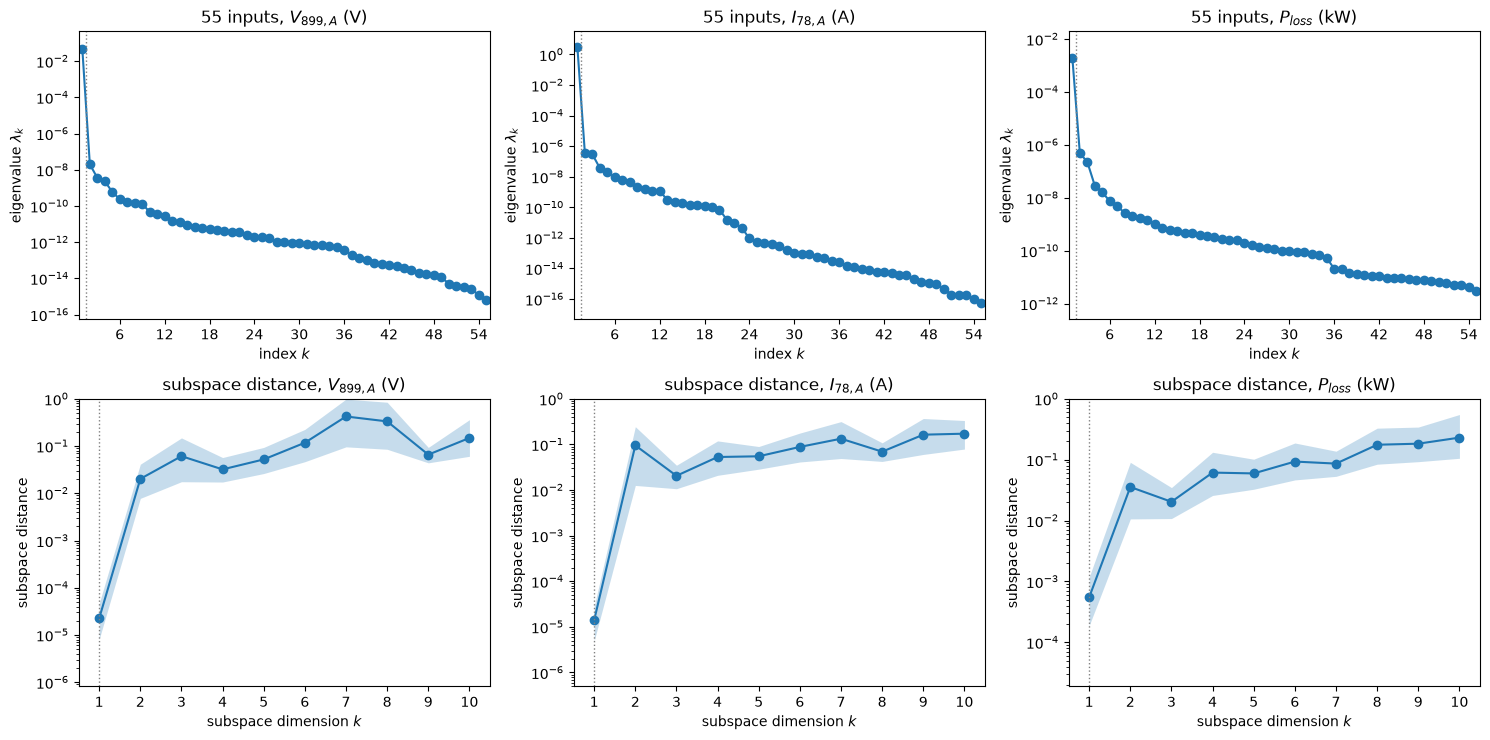

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for c, q in enumerate(QOI):
    ac.plotting.plot_eigenvalues(sub55[q], ax=axes[0, c])
    axes[0, c].set_title(f'55 inputs, {QLAB[q]}')
    ac.plotting.plot_subspace_errors(sub55[q], k_max=10, ax=axes[1, c])
    axes[1, c].set_title(f'subspace distance, {QLAB[q]}')
fig.tight_layout()
plt.close(fig)
for q in QOI:
    d = sub55[q].bootstrap_distances.mean(axis=0)
    print(f'{q:5s}: bootstrap mean subspace distance, k = 1, 2, 3: ' + ', '.join(f'{v:.1e}' for v in d[:3]))
fig

The bootstrap bands are narrow, and the one-dimensional subspace is very well determined: its mean bootstrap distance is $2.2\times10^{-5}$ for the voltage, $1.4\times10^{-5}$ for the current and $5.5\times10^{-4}$ for the loss, against $10^{-2}$ to $10^{-1}$ for $k = 2$ and 3.

**First eigenvectors.** Bar colours give the phase of each load.

V899A: largest |w1|: LOAD55 (A) -0.371, LOAD52 (A) -0.371, LOAD51 (A) -0.279, LOAD54 (A) -0.279, LOAD46 (A) -0.239, LOAD49 (A) -0.239; share of w1^2 by phase A/B/C: 0.893/0.104/0.003; components of sign +/-: 34/21
I78A : largest |w1|: LOAD9 (A) +0.247, LOAD14 (A) +0.246, LOAD21 (A) +0.245, LOAD55 (A) +0.245, LOAD52 (A) +0.245, LOAD51 (A) +0.244; share of w1^2 by phase A/B/C: 1.000/0.000/0.000; components of sign +/-: 51/4
PLOSS: largest |w1|: LOAD53 (B) +0.268, LOAD50 (B) +0.265, LOAD35 (B) +0.252, LOAD45 (B) +0.247, LOAD41 (B) +0.247, LOAD26 (B) +0.247; share of w1^2 by phase A/B/C: 0.126/0.846/0.028; components of sign +/-: 40/15


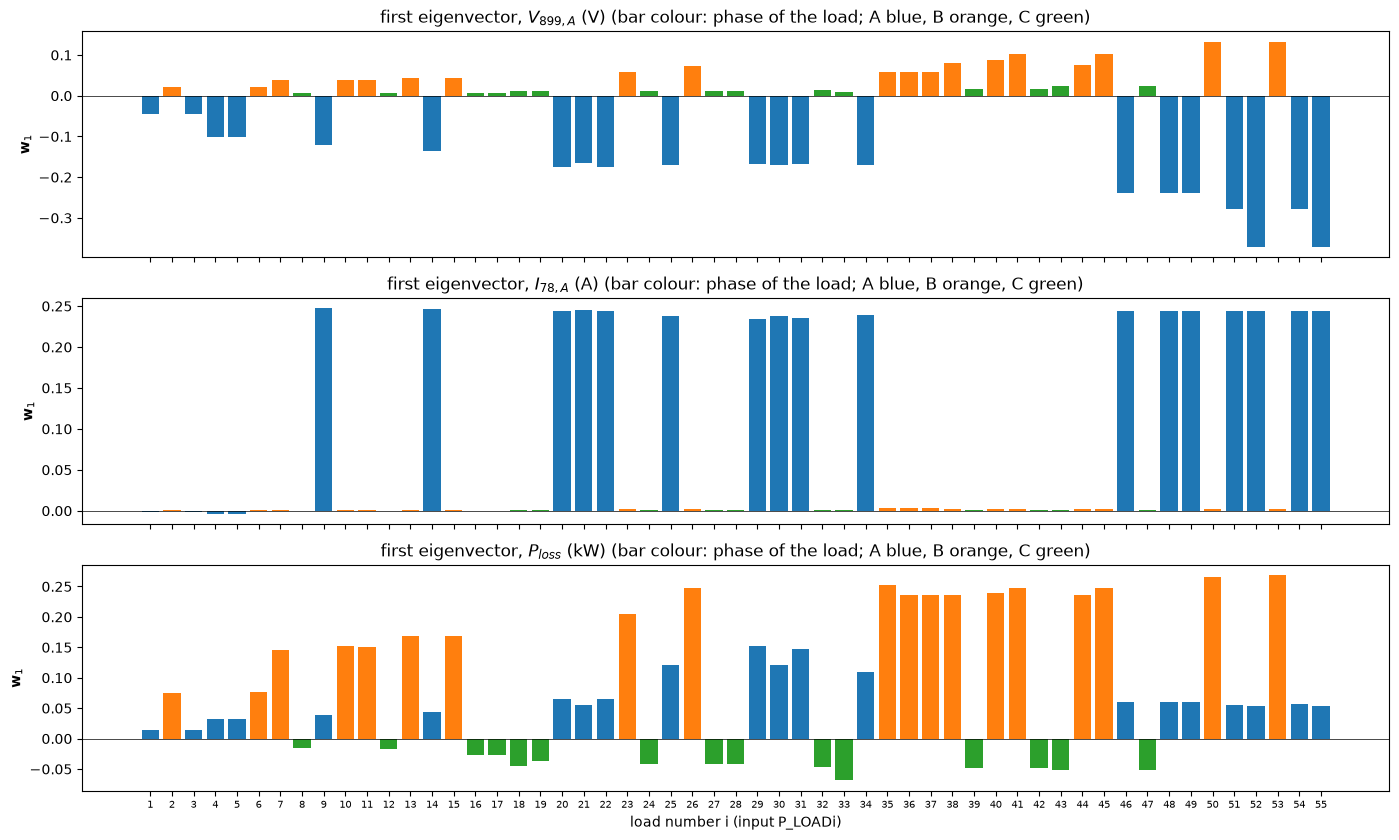

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(14, 8.5), sharex=True)
for ax, q in zip(axes, QOI):
    w = sub55[q].W[:, 0]
    ax.bar(np.arange(1, 56), w, color=[PCOL[p] for p in PH])
    ax.axhline(0, color='k', lw=.5)
    ax.set_ylabel(r'$\mathbf{w}_1$')
    ax.set_title(f'first eigenvector, {QLAB[q]} (bar colour: phase of the load; A blue, B orange, C green)')
axes[-1].set_xticks(range(1, 56))
axes[-1].set_xticklabels([str(k) for k in range(1, 56)], fontsize=7)
axes[-1].set_xlabel('load number i (input P_LOADi)')
fig.tight_layout()
plt.close(fig)
for q in QOI:
    w = sub55[q].W[:, 0]
    o = np.argsort(-np.abs(w))[:6]
    share = {p: np.sum(w[PH == p]**2) for p in 'ABC'}
    print(f'{q:5s}: largest |w1|: ' + ', '.join(f'LOAD{i + 1} ({PH[i]}) {w[i]:+.3f}' for i in o)
          + '; share of w1^2 by phase A/B/C: ' + '/'.join(f'{share[p]:.3f}' for p in 'ABC')
          + f'; components of sign +/-: {np.sum(w > 0)}/{np.sum(w < 0)}')
fig

The voltage's direction is a weighted sum of the loads on phase A, which carry 0.893 of $\|\mathbf w_1\|^2$: the largest weights belong to the loads at the far end of the feeder near bus 899, LOAD55 and LOAD52 ($-0.371$ each), LOAD51 and LOAD54 ($-0.279$), LOAD46 and LOAD49 ($-0.239$). They are negative because more phase-A demand downstream lowers the phase-A voltage. The loads on phases B and C enter with the opposite sign (34 positive components in all) and 0.104 and 0.003 of $\|\mathbf w_1\|^2$: the lines are given by sequence impedances with $R_0 \ne R_1$, which couple the phases, and in this unbalanced feeder current on phases B and C raises the phase-A voltage through that coupling. The current in line 78, upstream of most of the feeder, is the sum of the downstream phase-A demands: its direction is almost uniform over the 17 phase-A loads downstream of the line (components 0.235 to 0.247), and the other 38 components, among them the four phase-A loads upstream of it (LOAD1, LOAD3, LOAD4, LOAD5), are below 0.003 in magnitude. The loss direction is led by the heavily loaded phase B (0.846 of $\|\mathbf w_1\|^2$), headed by LOAD53, LOAD50 and LOAD35.

**Sufficient summary plots** with the quadratic fit in $y_1$:

V899A: leave-one-out R^2, linear in y1 0.9999987 (1 - R^2 = 1.31e-06); quadratic 0.9999996 (1 - R^2 = 3.93e-07)
I78A : leave-one-out R^2, linear in y1 0.9999989 (1 - R^2 = 1.09e-06); quadratic 0.9999998 (1 - R^2 = 1.59e-07)
PLOSS: leave-one-out R^2, linear in y1 0.9996878 (1 - R^2 = 3.12e-04); quadratic 0.9997914 (1 - R^2 = 2.09e-04)


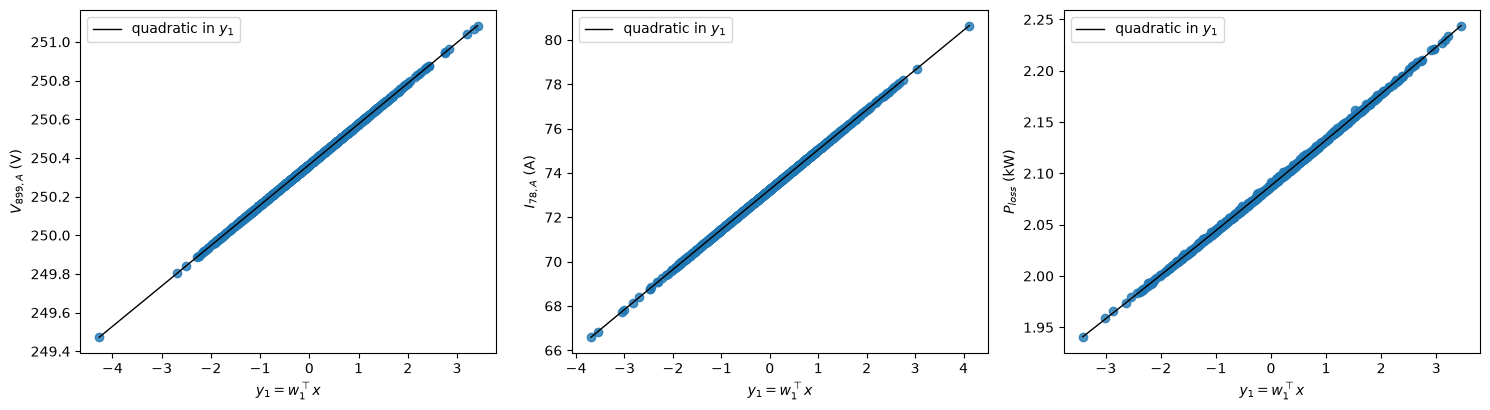

In [8]:
sur55 = {q: {d: ac.fit_surrogate(X=X55, f=F55[:, i], subspace=sub55[q], kind='poly', degree=d) for d in (1, 2)}
         for i, q in enumerate(QOI)}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (i, q) in zip(axes, enumerate(QOI)):
    ac.plotting.plot_sufficient_summary(sub55[q], X=X55, f=F55[:, i], dims=1, qoi_label=QLAB[q], ax=ax)
    y = space55.to_normalized(X55) @ sub55[q].W[:, 0]
    yy = np.linspace(y.min(), y.max(), 100)
    ax.plot(yy, sur55[q][2].evaluate(yy[:, None]), 'k-', lw=1, label='quadratic in $y_1$')
    ax.legend()
fig.tight_layout()
plt.close(fig)
for q in QOI:
    print(f'{q:5s}: leave-one-out R^2, linear in y1 {sur55[q][1].loo_r_squared:.7f} (1 - R^2 = '
          f'{1 - sur55[q][1].loo_r_squared:.2e}); quadratic {sur55[q][2].loo_r_squared:.7f} '
          f'(1 - R^2 = {1 - sur55[q][2].loo_r_squared:.2e})')
fig

All three summary plots are straight lines without visible scatter. A linear function of $y_1$ has leave-one-out $R^2$ = 0.9999987 for the voltage ($1 - R^2 = 1.31\times10^{-6}$), 0.9999989 for the current ($1.09\times10^{-6}$) and 0.9996878 for the loss ($3.12\times10^{-4}$); a quadratic lowers $1 - R^2$ to $3.93\times10^{-7}$, $1.59\times10^{-7}$ and $2.09\times10^{-4}$. The loss is quadratic in the branch currents, which is why its residual is larger.

In [9]:
# How far is V899A from linear in the loads? Compare the gradients over the sample, in sd units.
for q in QOI:
    Gn = G55[q] * od.SD55
    gbar = Gn.mean(0)
    rel = np.linalg.norm(Gn - gbar, axis=1) / np.linalg.norm(gbar)
    print(f'{q:5s}: |grad - mean grad| / |mean grad| over the 1000 samples: median {np.median(rel):.1e}, '
          f'max {rel.max():.1e}; |mean grad| = {np.linalg.norm(gbar):.4g} {od.QOI_UNITS[QOI.index(q)]} per sd')
w = sub55['V899A'].W[:, 0]
g = G55['V899A'].mean(0)
print('mean dV899A/dP_i (V/kW) by phase of load i:',
      '; '.join(f'{p}: {g[PH == p].min():+.3f} to {g[PH == p].max():+.3f}' for p in 'ABC'))
wI = sub55['I78A'].W[:, 0]
big = np.abs(wI) > 0.1
print(f'I78A: {big.sum()} components above 0.1 in magnitude (phases {"".join(sorted(set(PH[big])))}), {wI[big].min():.3f} to '
      f'{wI[big].max():.3f}; the other {np.sum(~big)} are below {np.abs(wI[~big]).max():.3f} in magnitude, among them the '
      'phase-A loads ' + ', '.join(f'LOAD{i + 1}' for i in np.where(~big & (PH == 'A'))[0]))
print(f'|w1(V899A) . w1(I78A)| = {abs(w @ sub55["I78A"].W[:, 0]):.3f}, '
      f'|w1(V899A) . w1(PLOSS)| = {abs(w @ sub55["PLOSS"].W[:, 0]):.3f}')
for i, q in enumerate(QOI):
    b = np.linalg.lstsq(np.column_stack([np.ones(len(Z55)), Z55]), F55[:, i], rcond=None)[0][1:]
    print(f'{q:5s}: |cos(w1, least-squares slope on the standardized inputs)| = '
          f'{abs(sub55[q].W[:, 0] @ b) / np.linalg.norm(b):.7f}')

V899A: |grad - mean grad| / |mean grad| over the 1000 samples: median 1.2e-03, max 5.8e-03; |mean grad| = 0.2099 V per sd
I78A : |grad - mean grad| / |mean grad| over the 1000 samples: median 1.0e-03, max 5.9e-03; |mean grad| = 1.8 A per sd
PLOSS: |grad - mean grad| / |mean grad| over the 1000 samples: median 2.1e-02, max 6.7e-02; |mean grad| = 0.04417 kW per sd
mean dV899A/dP_i (V/kW) by phase of load i: A: -0.778 to -0.096; B: +0.044 to +0.279; C: +0.014 to +0.050
I78A: 17 components above 0.1 in magnitude (phases A), 0.235 to 0.247; the other 38 are below 0.003 in magnitude, among them the phase-A loads LOAD1, LOAD3, LOAD4, LOAD5
|w1(V899A) . w1(I78A)| = 0.880, |w1(V899A) . w1(PLOSS)| = 0.003
V899A: |cos(w1, least-squares slope on the standardized inputs)| = 1.0000000
I78A : |cos(w1, least-squares slope on the standardized inputs)| = 1.0000000
PLOSS: |cos(w1, least-squares slope on the standardized inputs)| = 0.9999901


The reason for the one-dimensional structure is that the responses are nearly linear in the load powers over the sampled range: the gradient of $V_{899,A}$ (in standard-deviation units) differs from its mean by a median of $1.2\times10^{-3}$ of the mean's norm (at most $5.8\times10^{-3}$), and that of the loss by $2.1\times10^{-2}$ (at most $6.7\times10^{-2}$). A nearly constant gradient gives a $\mathbf C$ of nearly rank one, whose eigenvector is the mean gradient. So in the base scenario the active direction is the linear sensitivity vector: $\mathbf w_1$ and the least-squares slope of each QoI on the standardized inputs agree to $|\cos|$ = 1.0000000 (voltage), 1.0000000 (current) and 0.9999901 (loss), and an ordinary regression on the inputs would find the same direction. The eigenvalue ratios of $10^{3}$ to $10^{6}$ measure how little the gradient varies over the sample ($1 - \lambda_1/\mathrm{trace} = 6.2\times10^{-7}$ for the voltage is of the order of the square of its $1.2\times10^{-3}$ median deviation), not a nonlinear low-dimensional structure. The sensitivities of $V_{899,A}$ are $-0.778$ to $-0.096$ V/kW for phase-A loads, $+0.044$ to $+0.279$ V/kW for phase-B loads and $+0.014$ to $+0.050$ V/kW for phase-C loads. The voltage and current directions are close ($|\mathbf w_1^{V}\cdot\mathbf w_1^{I}| = 0.880$), and the voltage and loss directions are nearly orthogonal (0.003).

### Results: 110 inputs (load powers and power factors)

The power factors are uniform, so a uniform-to-$[-1,1]$ map would scale them by their half-range, $\sqrt3$ times their standard deviation, while the Gaussian powers are scaled by their standard deviation. To scale every input in the same way, by its standard deviation (0.1 kW for the powers, $0.1/\sqrt{12} = 0.02887$ for the power factors), we describe the inputs to the library with `ac.Gaussian` with the inputs' means and variances. This object is used only for the scaling: the power-factor samples stay uniform. As a check we repeat the estimate with the library's half-range scaling of the power factors (`ac.Product`).

In [10]:
# Every input is scaled by its standard deviation (P_i: 0.1 kW; pf_i: 0.1/sqrt(12)). The Gaussian space
# with the inputs' means and variances is used for this scaling only; the pf samples are uniform.
space110 = ac.Gaussian(od.MEAN110, od.SD110**2, names=od.NAMES110, units=od.UNITS110)
sub110 = {}
for i, q in enumerate(QOI):
    s = ac.active_subspace(space=space110, X=X110, f=F110[:, i], grads=G110[q], estimator='as', n=1,
                           nboot=500, rng=SEED)
    sub110[q] = ac.orient(s, by='mean_gradient', grads=G110[q])
    lam = s.eigenvalues
    k_hat = ac.dimension_criterion(s, rule='evg')[2]
    d = s.bootstrap_distances.mean(axis=0)
    print(f'{q:5s}: eigenvalues {np.array2string(lam[:5], precision=3)} ...; lambda1/lambda2 = {lam[0] / lam[1]:.1f}, '
          f'lambda2/lambda3 = {lam[1] / lam[2]:.2f}; 1 - lambda1/trace = {1 - lam[0] / lam.sum():.1e}; '
          f'gap rule n = {k_hat}; bootstrap distance k = 1, 2: {d[0]:.4f}, {d[1]:.3f}')
# The same with the library's default scaling for a uniform input (half-range, = sqrt(3) sd)
spaceP = ac.Product([ac.Gaussian(od.MEAN55, od.SD55**2), ac.Uniform(np.full(55, od.PF_LO), np.full(55, od.PF_HI))])
for i, q in enumerate(QOI):
    sP = ac.active_subspace(space=spaceP, X=X110, f=F110[:, i], grads=G110[q], estimator='as', n=1)
    wP = spaceP.directions_to_physical(sP.W[:, :1])[:, 0]
    wS = space110.directions_to_physical(sub110[q].W[:, :1])[:, 0]
    print(f'{q:5s}: half-range scaling of pf: lambda1/lambda2 = {sP.eigenvalues[0] / sP.eigenvalues[1]:.1f}; '
          f'|cos| between the two leading directions in physical units = '
          f'{abs(wP @ wS) / np.linalg.norm(wP) / np.linalg.norm(wS):.4f}')
for i, q in enumerate(QOI):
    b = np.linalg.lstsq(np.column_stack([np.ones(len(Z110)), Z110]), F110[:, i], rcond=None)[0][1:]
    print(f'{q:5s}: |cos(w1, least-squares slope on the standardized inputs)| = '
          f'{abs(sub110[q].W[:, 0] @ b) / np.linalg.norm(b):.5f}')

V899A: eigenvalues [9.139e-02 1.367e-04 5.000e-05 2.444e-05 2.155e-05] ...; lambda1/lambda2 = 668.7, lambda2/lambda3 = 2.73; 1 - lambda1/trace = 4.1e-03; gap rule n = 1; bootstrap distance k = 1, 2: 0.0020, 0.050


I78A : eigenvalues [6.280e+00 2.481e-03 1.585e-03 1.160e-03 3.233e-04] ...; lambda1/lambda2 = 2531.4, lambda2/lambda3 = 1.57; 1 - lambda1/trace = 1.9e-03; gap rule n = 1; bootstrap distance k = 1, 2: 0.0013, 0.088


PLOSS: eigenvalues [7.674e-03 1.397e-05 2.920e-06 1.009e-06 8.449e-07] ...; lambda1/lambda2 = 549.2, lambda2/lambda3 = 4.79; 1 - lambda1/trace = 3.8e-03; gap rule n = 1; bootstrap distance k = 1, 2: 0.0019, 0.034
V899A: half-range scaling of pf: lambda1/lambda2 = 533.9; |cos| between the two leading directions in physical units = 1.0000
I78A : half-range scaling of pf: lambda1/lambda2 = 1647.8; |cos| between the two leading directions in physical units = 1.0000
PLOSS: half-range scaling of pf: lambda1/lambda2 = 477.7; |cos| between the two leading directions in physical units = 1.0000
V899A: |cos(w1, least-squares slope on the standardized inputs)| = 0.99989
I78A : |cos(w1, least-squares slope on the standardized inputs)| = 0.99994
PLOSS: |cos(w1, least-squares slope on the standardized inputs)| = 0.99983


The gap is smaller than in the base scenario but still large: $\lambda_1/\lambda_2$ = 668.7 for the voltage, 2531.4 for the current and 549.2 for the loss, with $\lambda_2/\lambda_3$ = 2.73, 1.57 and 4.79 after it, and the eigenvalues after the first hold $4.1\times10^{-3}$, $1.9\times10^{-3}$ and $3.8\times10^{-3}$ of the trace. The gap rule picks $n = 1$, and the mean bootstrap distance is 0.0020, 0.0013 and 0.0019 for $k = 1$. With the half-range scaling of the power factors the ratios are 533.9, 1647.8 and 477.7, and the leading direction in physical units is the same (|cos| = 1.0000 to four digits): for a nearly linear response the leading direction is the mean gradient whatever the scaling, and only the eigenvalues change. Here too $\mathbf w_1$ is close to the least-squares slope direction ($|\cos|$ = 0.99989, 0.99994 and 0.99983), but the power factors add curvature, which shows in the eigenvalues after the first and in the surrogate residuals below.

V899A: largest |w1|: pf_LOAD26 (B) -0.542, P_LOAD52 (A) -0.264, P_LOAD55 (A) -0.264, pf_LOAD53 (B) -0.248, pf_LOAD29 (A) +0.234, P_LOAD51 (A) -0.200; share of w1^2 on the P_i 0.525, on the pf_i 0.475
I78A : largest |w1|: pf_LOAD29 (A) -0.625, P_LOAD9 (A) +0.187, P_LOAD14 (A) +0.186, P_LOAD21 (A) +0.186, P_LOAD51 (A) +0.185, P_LOAD48 (A) +0.185; share of w1^2 on the P_i 0.573, on the pf_i 0.427
PLOSS: largest |w1|: pf_LOAD29 (A) -0.651, pf_LOAD26 (B) -0.425, P_LOAD53 (B) +0.152, P_LOAD50 (B) +0.150, P_LOAD35 (B) +0.144, pf_LOAD31 (A) -0.140; share of w1^2 on the P_i 0.320, on the pf_i 0.680
P_L of loads 26, 29, 53: [12.659 10.471  3.087] kW; phases ['B' 'A' 'B']


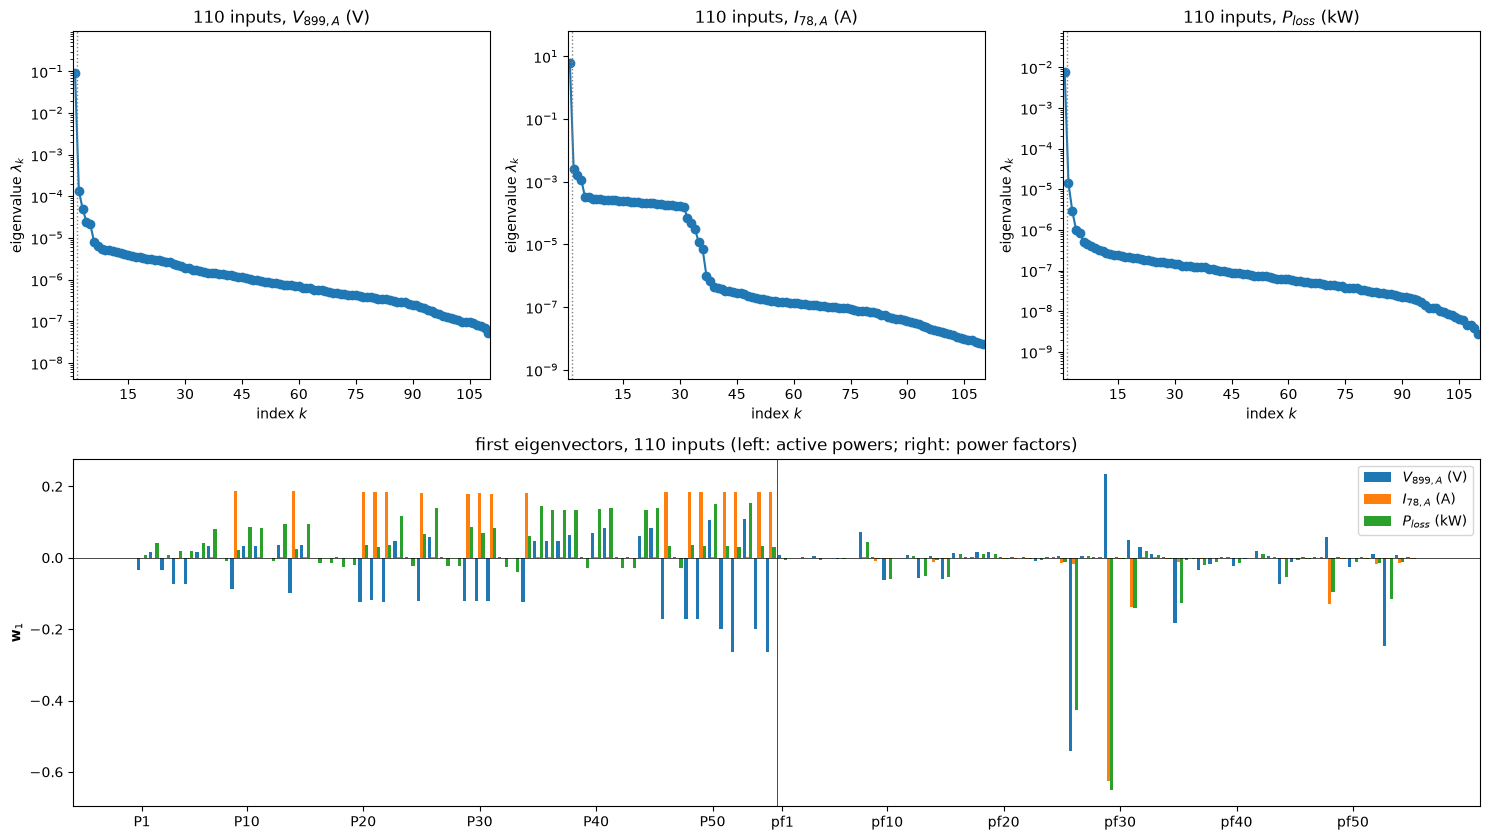

In [11]:
fig = plt.figure(figsize=(15, 8.5))
gs = fig.add_gridspec(2, 3)
for c, q in enumerate(QOI):
    ax = fig.add_subplot(gs[0, c])
    ac.plotting.plot_eigenvalues(sub110[q], ax=ax)
    ax.set_title(f'110 inputs, {QLAB[q]}')
ax = fig.add_subplot(gs[1, :])
for k, q in enumerate(QOI):
    ax.bar(np.arange(110) + (k - 1) * 0.28, sub110[q].W[:, 0], width=0.28, label=QLAB[q])
ax.axvline(54.5, color='k', lw=.5)
ax.axhline(0, color='k', lw=.5)
ax.set_xticks([0, 9, 19, 29, 39, 49, 55, 64, 74, 84, 94, 104])
ax.set_xticklabels(['P1', 'P10', 'P20', 'P30', 'P40', 'P50', 'pf1', 'pf10', 'pf20', 'pf30', 'pf40', 'pf50'])
ax.set_ylabel(r'$\mathbf{w}_1$')
ax.set_title('first eigenvectors, 110 inputs (left: active powers; right: power factors)')
ax.legend()
fig.tight_layout()
plt.close(fig)
for q in QOI:
    w = sub110[q].W[:, 0]
    o = np.argsort(-np.abs(w))[:6]
    lab = lambda j: (f'P_LOAD{j + 1}' if j < 55 else f'pf_LOAD{j - 54}') + f' ({PH[j % 55]})'
    print(f'{q:5s}: largest |w1|: ' + ', '.join(f'{lab(j)} {w[j]:+.3f}' for j in o)
          + f'; share of w1^2 on the P_i {np.sum(w[:55]**2):.3f}, on the pf_i {np.sum(w[55:]**2):.3f}')
print('P_L of loads 26, 29, 53:', od.P_REF[[25, 28, 52]], 'kW; phases', PH[[25, 28, 52]])
fig

The power factors of the few large loads now share the leading direction with the active powers. For the voltage, the active powers carry 0.525 of $\|\mathbf w_1\|^2$ and the power factors 0.475; the largest component is the power factor of LOAD26 ($-0.542$), the 12.659 kW load on phase B: a lower power factor there means more reactive current on phase B, which raises the phase-A voltage, as phase-B demand does in the base scenario. The phase-A powers near bus 899 (LOAD52 and LOAD55, $-0.264$ each) follow, then the power factors of LOAD53 (phase B, $-0.248$) and of LOAD29 (the 10.471 kW load on phase A, $+0.234$). The current in line 78 is led by the power factor of LOAD29 ($-0.625$), and the loss by the power factors of LOAD29 and LOAD26 ($-0.651$ and $-0.425$; the power factors hold 0.680 of $\|\mathbf w_1\|^2$).

**Sufficient summary plots** (110 inputs):

V899A: 1 - LOO R^2: linear in y1 1.36e-03, quadratic in y1 1.35e-03, quadratic in (y1, y2) 9.79e-04
I78A : 1 - LOO R^2: linear in y1 9.77e-04, quadratic in y1 9.60e-04, quadratic in (y1, y2) 7.88e-04
PLOSS: 1 - LOO R^2: linear in y1 1.98e-03, quadratic in y1 1.71e-03, quadratic in (y1, y2) 8.70e-04


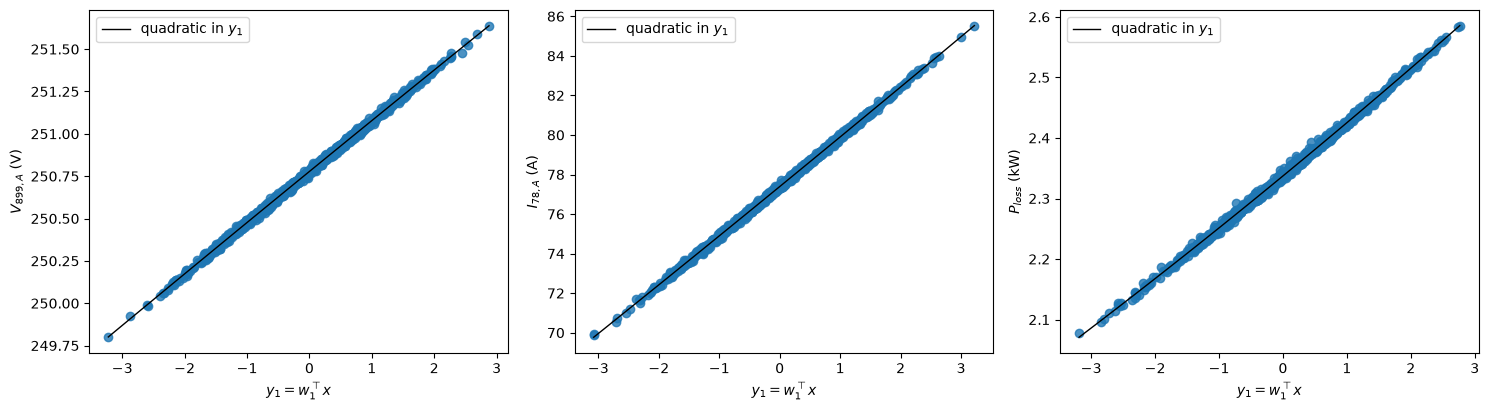

In [12]:
sur110 = {q: {d: ac.fit_surrogate(X=X110, f=F110[:, i], subspace=sub110[q], kind='poly', degree=d) for d in (1, 2)}
          for i, q in enumerate(QOI)}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (i, q) in zip(axes, enumerate(QOI)):
    ac.plotting.plot_sufficient_summary(sub110[q], X=X110, f=F110[:, i], dims=1, qoi_label=QLAB[q], ax=ax)
    y = space110.to_normalized(X110) @ sub110[q].W[:, 0]
    yy = np.linspace(y.min(), y.max(), 100)
    ax.plot(yy, sur110[q][2].evaluate(yy[:, None]), 'k-', lw=1, label='quadratic in $y_1$')
    ax.legend()
fig.tight_layout()
plt.close(fig)
for q in QOI:
    s2 = ac.active_subspace(space=space110, X=X110, f=F110[:, QOI.index(q)], grads=G110[q], estimator='as', n=2)
    r2 = ac.fit_surrogate(X=X110, f=F110[:, QOI.index(q)], subspace=s2, kind='poly', degree=2).loo_r_squared
    print(f'{q:5s}: 1 - LOO R^2: linear in y1 {1 - sur110[q][1].loo_r_squared:.2e}, quadratic in y1 '
          f'{1 - sur110[q][2].loo_r_squared:.2e}, quadratic in (y1, y2) {1 - r2:.2e}')
fig

The summary plots show a clear linear trend with a little scatter. A linear function of $y_1$ has $1 - R^2_{\rm LOO}$ = $1.36\times10^{-3}$ (voltage), $9.77\times10^{-4}$ (current) and $1.98\times10^{-3}$ (loss); a quadratic in $y_1$ hardly helps ($1.35\times10^{-3}$, $9.60\times10^{-4}$, $1.71\times10^{-3}$), and a quadratic in $(y_1, y_2)$ lowers them to $9.79\times10^{-4}$, $7.88\times10^{-4}$ and $8.70\times10^{-4}$. The power factor enters $Q = P\tan(\arccos\mathrm{pf})$ nonlinearly, which is why the residuals of the voltage and the current are about a thousand times those of the base scenario.

**Choice of dimension.** We take $n = 1$ for every QoI in both scenarios. The first eigenvalue gap is the only large one ($\lambda_1/\lambda_2$ from 549 to $8.5\times10^{6}$; $\lambda_2/\lambda_3$ is 1.30–5.57), the gap rule picks $n = 1$, the one-dimensional subspaces have bootstrap distances of $2.0\times10^{-3}$ or less, and a function of $y_1$ alone has leave-one-out $R^2$ of at least 0.9996878 (base scenario) and 0.998 (110 inputs, where $1 - R^2_{\rm LOO} \le 1.98\times10^{-3}$). A second active variable lowers $1 - R^2_{\rm LOO}$ only from $1.36\times10^{-3}$ to $9.79\times10^{-4}$ for the 110-input voltage, which does not justify it. In the base scenario the very large ratios follow from near-linearity, which makes $n = 1$ almost automatic there; they are not evidence of nonlinear structure. The 110-input case, with ratios of 549 to 2531 and residual curvature, is the more informative test of the one-dimensional description.

### Comparison with the paper: the distribution of $V_{899,A}$

The paper's reference is a Latin hypercube PPF with $10^5$ trials in the base scenario, and its Table VIII (p. 702) gives three probabilities for $U_A = V_{899,A}$. We compare them with our 10 000-point Latin hypercube set (with binomial 95 % intervals, which are conservative for a Latin hypercube) and with the linear and quadratic functions of $y_1$ fitted to the 1000 gradient samples, evaluated at the 10 000 Latin hypercube inputs; the latter plays the role of the paper's surrogate-based PPF.

                          paper (LHS, 1e5)   model, LHS 1e4 [95 % binomial]  linear in y1  quadratic
P(V <= 250)                          4.06%             4.13% [ 3.76,  4.54]         4.15%      4.12%
P(250.4 < V <= 250.8)               41.57%            41.21% [40.25, 42.18]        41.29%     41.23%
P(V > 250.8)                         1.94%             2.18% [ 1.91,  2.49]         2.16%      2.17%
model               : mean 250.3657 V, sd 0.2119 V, skewness +0.046, kurtosis 2.926, range 249.56-251.17 V
linear surrogate    : mean 250.3657 V, sd 0.2119 V, skewness +0.042, kurtosis 2.925, range 249.56-251.17 V
quadratic surrogate : mean 250.3657 V, sd 0.2119 V, skewness +0.046, kurtosis 2.926, range 249.56-251.17 V
validation R^2 of the surrogates on the 10 000 LHS points: linear 0.9999988, quadratic 0.9999997
Table VIII probabilities with the 10 000 LHS voltages shifted by dV: -0.05 V: 6.74/33.15/1.12 %; -0.02 V: 5.02/38.09/1.67 %; +0.02 V: 3.21/44.37/2.71 %; +0.05 V: 2.12/49.14/3.67 

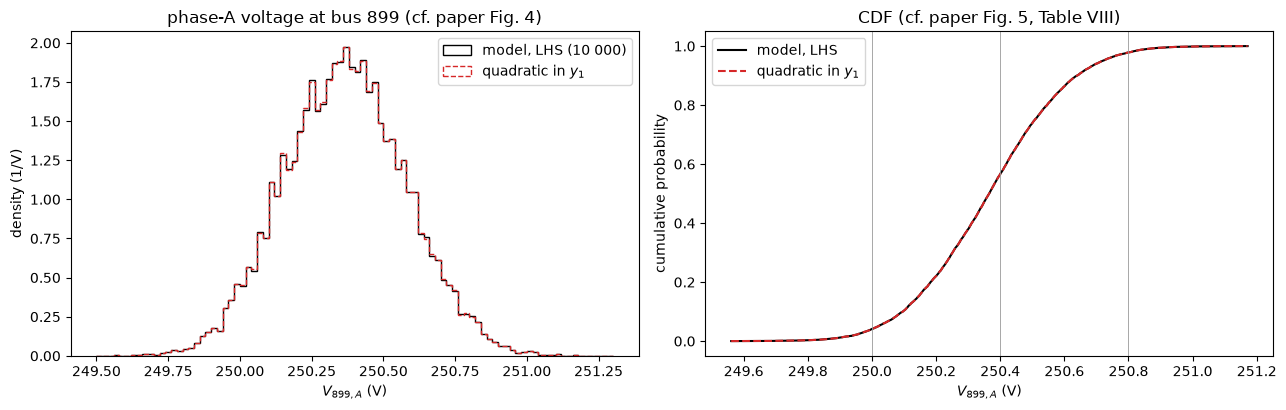

In [13]:
V = FL[:, 0]
def probs(v):
    return np.array([np.mean(v <= 250), np.mean((v > 250.4) & (v <= 250.8)), np.mean(v > 250.8)]) * 100
def wilson(p, n, z=1.96):
    p = p / 100
    c = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return 100 * (c - h), 100 * (c + h)
paper = np.array([4.06, 41.57, 1.94])        # Table VIII, LHS row (p. 702)
lab = ['P(V <= 250)', 'P(250.4 < V <= 250.8)', 'P(V > 250.8)']
p_lhs = probs(V)
sur_lin = ac.predict(sur55['V899A'][1], XL)
sur_quad = ac.predict(sur55['V899A'][2], XL)
print(f'{"":24s} {"paper (LHS, 1e5)":>17s} {"model, LHS 1e4 [95 % binomial]":>32s} {"linear in y1":>13s} {"quadratic":>10s}')
for k in range(3):
    lo, hi = wilson(p_lhs[k], len(V))
    print(f'{lab[k]:24s} {paper[k]:16.2f}% {p_lhs[k]:16.2f}% [{lo:5.2f}, {hi:5.2f}] {probs(sur_lin)[k]:12.2f}% '
          f'{probs(sur_quad)[k]:9.2f}%')
for name, v in [('model', V), ('linear surrogate', sur_lin), ('quadratic surrogate', sur_quad)]:
    print(f'{name:20s}: mean {v.mean():.4f} V, sd {v.std(ddof=1):.4f} V, skewness {stats.skew(v):+.3f}, '
          f'kurtosis {stats.kurtosis(v, fisher=False):.3f}, range {v.min():.2f}-{v.max():.2f} V')
print(f'validation R^2 of the surrogates on the 10 000 LHS points: linear {1 - np.mean((sur_lin - V)**2) / V.var():.7f}, '
      f'quadratic {1 - np.mean((sur_quad - V)**2) / V.var():.7f}')
print('Table VIII probabilities with the 10 000 LHS voltages shifted by dV: ' + '; '.join(
      f'{dv:+.2f} V: ' + '/'.join(f'{p:.2f}' for p in probs(V + dv)) + ' %' for dv in (-0.05, -0.02, 0.02, 0.05)))
print(f'nominal point (all P_i = P_Li, pf 0.95): V899 phases A, B, C = {NOM[0, 1]:.3f}, {NOM[0, 2]:.3f}, '
      f'{NOM[0, 3]:.3f} V; I78A = {NOM[0, 4]:.3f} A; PLOSS = {NOM[0, 5]:.4f} kW; with pf 0.90: V899A = {NOM[1, 1]:.3f} V')
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
edges = np.arange(249.5, 251.31, 0.02)
axes[0].hist(V, bins=edges, density=True, histtype='step', color='k', label='model, LHS (10 000)')
axes[0].hist(sur_quad, bins=edges, density=True, histtype='step', color='C3', ls='--', label='quadratic in $y_1$')
axes[0].set_xlabel(QLAB['V899A']); axes[0].set_ylabel('density (1/V)')
axes[0].set_title('phase-A voltage at bus 899 (cf. paper Fig. 4)'); axes[0].legend()
vv = np.sort(V)
axes[1].plot(vv, np.arange(1, len(vv) + 1) / len(vv), 'k-', label='model, LHS')
axes[1].plot(np.sort(sur_quad), np.arange(1, len(vv) + 1) / len(vv), 'C3--', label='quadratic in $y_1$')
for t in (250.0, 250.4, 250.8):
    axes[1].axvline(t, color='0.6', lw=.6)
axes[1].set_xlabel(QLAB['V899A']); axes[1].set_ylabel('cumulative probability')
axes[1].set_title('CDF (cf. paper Fig. 5, Table VIII)'); axes[1].legend()
fig.tight_layout()
plt.close(fig)
fig

The model's probabilities are consistent with the paper's Table VIII: $P(V \le 250)$ is 4.13 % [3.76, 4.54] against 4.06 %, $P(250.4 < V \le 250.8)$ is 41.21 % [40.25, 42.18] against 41.57 %, and $P(V > 250.8)$ is 2.18 % [1.91, 2.49] against 1.94 %; all three paper values lie inside our intervals. This is not an independent confirmation, because Table VIII was used to choose the two settings the paper leaves open, among four combinations (`check_accuracy.py`, 2000 Monte Carlo samples, probabilities in the order above): sd 0.1 kW with OpenDSS's default switch to constant impedance above 1.05 p.u. (the reading used here) gives 4.50 %, 40.40 % and 1.70 %; sd $0.1\,P_{L_i}$ with the switch 22.85 %, 29.85 % and 16.75 %; sd 0.1 kW with constant power at every voltage 0.05 %, 67.15 % and 18.45 %; and sd $0.1\,P_{L_i}$ with constant power 10.60 %, 32.55 % and 35.00 %. The paper's Figs. 4–5 support the chosen readings independently: the relative sd gives a standard deviation of $V_{899,A}$ of 0.460 V (`check_accuracy.py`), too wide for the span of Fig. 4, and constant power gives a nominal $V_{899,A}$ of 250.626 V (`check_accuracy.py`), while the CDF of Fig. 5 crosses 0.5 near 250.37 V (read from the figure). Table VIII discriminates so sharply because it pins the mean of the voltage to a few hundredths of a volt: shifting our 10 000 voltages by $-0.02$ or $+0.02$ V moves $P(V \le 250)$ to 5.02 % or 3.21 %, outside the interval [3.76, 4.54].

The same comparison bears on the negative load powers (`check_accuracy.py`, all 10 000 Latin hypercube rows rerun): with every negative power set to 0 the three probabilities become 6.07 %, 27.88 % and 0.27 % (mean voltage lower by 0.0743 V), and with the same stratified uniforms mapped through the normal truncated at 0 they become 17.90 %, 10.52 % and 0.00 %. Table VIII matches only when the negative powers are kept, so the paper's runs evidently kept them too.

The voltage has mean 250.3657 V and standard deviation 0.2119 V, skewness +0.046 and kurtosis 2.926, and ranges over 249.56–251.17 V, the span of the paper's Fig. 4 (249.6–251.2 V on its axis). At the nominal point the three phase voltages at bus 899 are 250.365, 238.421 and 253.414 V, where the paper's Fig. 3 histograms peak (near 250.4, 238.4 and 253.4 V, read from the figure). The one-variable surrogates reproduce the probabilities to within 0.08 percentage points and the mean and standard deviation to the printed digits (skewness +0.042 and +0.046, kurtosis 2.925 and 2.926 for the linear and quadratic fits), with validation $R^2$ of 0.9999988 (linear) and 0.9999997 (quadratic) on the 10 000 points.

| Quantity | Paper value | Notebook value |
|---|---|---|
| Feeder, solver | IEEE European LV Test Feeder [3], OpenDSS from MATLAB R2014a (p. 699) | the same feeder files, OpenDSS through OpenDSSDirect.py 0.9.4 (DSS C-API 0.14.5), tolerance $10^{-12}$ |
| Snapshot | on-peak, $t$ = 09:26:00 (p. 700) | load-shape point 566 (09:26) |
| Load powers, base scenario | $N(PL_i, 0.1^2)$, pf 0.95 (p. 700; Table I) | sd 0.1 kW (variance in kW$^2$), pf 0.95; chosen among four readings by matching Table VIII, consistent with Fig. 4 |
| Load model | "constant power" (p. 699) | OpenDSS constant power with default limits: constant impedance above 1.05 p.u. (43 of 55 loads at the nominal point); chosen by matching Table VIII, consistent with Fig. 5 |
| Negative load powers | not discussed | about 12 % of the sampled powers; kept (set to 0: 6.07 / 27.88 / 0.27 %, truncated normal: 17.90 / 10.52 / 0.00 % for the three Table VIII probabilities, `check_accuracy.py`) |
| 110-input case | 55 Gaussian powers + 55 pf $\sim U(0.85, 0.95)$ (p. 701; Table I); "Mixed" in Table IV | 55 Gaussian powers + 55 uniform pf |
| $V_{899}$, phases A, B, C | histogram peaks near 250.4, 238.4, 253.4 V (Fig. 3, read from the figure) | 250.365, 238.421, 253.414 V at the nominal point |
| $P(U_A \le 250)$ | 4.06 % (Table VIII, LHS $10^5$) | 4.13 % [3.76, 4.54] (LHS $10^4$) |
| $P(250.4 < U_A \le 250.8)$ | 41.57 % (Table VIII) | 41.21 % [40.25, 42.18] |
| $P(U_A > 250.8)$ | 1.94 % (Table VIII) | 2.18 % [1.91, 2.49] |
| Range of $U_A$ | axis 249.6–251.2 V (Fig. 4) | 249.56–251.17 V |
| Mean, variance, skewness, kurtosis of $U_A$ | not reported (only relative errors, Table VII) | 250.3657 V, sd 0.2119 V, +0.046, 2.926 |
| Surrogate error, $V_{899,A}$, 55 Gaussian inputs | relative $e_{LOO}$ $8.81\times10^{-7}$ (800 runs), $2.36\times10^{-6}$ (250 runs) (Table II) | $1 - R^2_{\rm LOO}$ $1.31\times10^{-6}$ (linear in $y_1$), $3.93\times10^{-7}$ (quadratic); 1000 runs |
| Surrogate error, $I_{78}$ and loss | $2.08\times10^{-6}$ and $3.97\times10^{-4}$ (Table V, 250 runs) | $1.09\times10^{-6}$ and $3.12\times10^{-4}$ (linear in $y_1$) |
| Surrogate error, $V_{899,A}$, 110 inputs | $3.67\times10^{-3}$ (Table IV, "Mixed", 250 runs) | $1.36\times10^{-3}$ (linear in $y_1$), $9.79\times10^{-4}$ (quadratic in $y_1, y_2$) |
| Active subspace | not computed | $n = 1$ for all QoIs; $\lambda_1/\lambda_2$ = $2.22\times10^{6}$, $8.49\times10^{6}$, $4.0\times10^{3}$ (55 inputs); 668.7, 2531.4, 549.2 (110 inputs) |
| Cost of one power flow | LHS, $10^5$ runs: $t_{pre}$ = 0.17 s, $t_{post}$ = 3561.86 s, $T_{total}$ = 3562.03 s (Table IX, p. 703; the text, p. 699, puts the power flows in $t_{pre}$, so table and text disagree); about 36 ms per run from $T_{total}$ | about 1.5 ms per solve (`DATA.md`) |

The paper's $e_{LOO}$ is the leave-one-out error of its sparse polynomial chaos expansion relative to the output variance (its Eq. (13), p. 697), which is $1 - R^2_{\rm LOO}$; its surrogates use all 55 or 110 inputs and 250 or 800 runs, ours one active variable and 1000 runs, so the comparison is of orders of magnitude. A function of one linear combination of the inputs reaches errors of the same order as the paper's adaptive expansion in 55 or 110 variables (whose 110-input row Table IV labels "Mixed").

### References

<a id="R1"></a>[1] F. Ni, P. H. Nguyen, and J. F. G. Cobben. [Basis-adaptive sparse polynomial chaos expansion for probabilistic power flow](https://doi.org/10.1109/TPWRS.2016.2558622). *IEEE Transactions on Power Systems*, 32(1):694–704, 2017.

[2] P. G. Constantine. [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860). SIAM, Philadelphia, 2015.

[3] K. P. Schneider, B. A. Mather, B. C. Pal, C.-W. Ten, G. J. Shirek, H. Zhu, J. C. Fuller, J. L. R. Pereira, L. F. Ochoa, L. R. de Araujo, R. C. Dugan, S. Matthias, S. Paudyal, T. E. McDermott, and W. Kersting. [Analytic considerations and design basis for the IEEE distribution test feeders](https://doi.org/10.1109/TPWRS.2017.2760011). *IEEE Transactions on Power Systems*, 33(3):3181–3188, 2018. (The feeder files: IEEE PES Distribution Test Feeders, the paper's ref. [33].)

[4] R. C. Dugan and T. E. McDermott. [An open source platform for collaborating on smart grid research](https://doi.org/10.1109/PES.2011.6039829). *2011 IEEE Power and Energy Society General Meeting*, pp. 1–7, 2011. (OpenDSS.)

In [14]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 39.7 s
